# Part 3: Run the analysis on our own data

In this notebook we apply the code from **Part 1** and **Part 2** to a recording that we made ourselves with MouseReMoCo, instead of the provided sample files (`001MoDe_R1.csv` and `001MoDe_R1.marker.csv`). The goal is to check that our analysis also works on new data.

## 1. Our data

- `data/generated_data.csv`: the mouse samples (`timestamp`, `mouseX`, `mouseY`, `mouseInTarget`).
- `data/generated_marker.csv`: the record start and end markers, followed by the summary table computed by MouseReMoCo.
- Recorded on 2026-11-14 with MouseReMoCo 1.3.0. The session contains 6 completed records of 20 s each.

- Protocol: `Rec001` to `Rec003` were done with the right hand and `Rec004` to `Rec006` with the left hand (our non-dominant hand), using the laptop's built-in mouse (no external mouse). 



## 2. What is different from the sample data

Our recording was made on a different screen with different task settings, so the task constants differ from the sample. We copied them from the header of our data file:

| Setting | Sample file | Our file |
|---|---|---|
| Screen (pixels) | 1104 x 661 | 1350 x 681 |
| Circle centre (pixels) | (552, 330) | (675, 340) |
| `TASK_RADIUS` (pixels) | 209.5 | 219.5 |
| `TASK_TOL` (pixels) | 47 | 47 |

Using the sample constants with our data would place the circle centre in the wrong spot and make every radius, and therefore every statistic, wrong.



Number of records found: 6
Record 1: rows 0 to 2201 (2201 samples)
Record 2: rows 2297 to 3930 (1633 samples)
Record 3: rows 4057 to 5759 (1702 samples)
Record 4: rows 5785 to 8246 (2461 samples)
Record 5: rows 8678 to 11030 (2352 samples)
Record 6: rows 11137 to 13460 (2323 samples)
Header line information in 'data/generated_data.csv':
  software: mouseReMoCo
  version: 1.3.0
  isWithLSL: false
  screenWidth: 1350
  screenHeight: 681
  centerX: 675
  centerY: 340
  autoStart: 3600
  cycleMaxNumber: 6
  cycleDuration: 20
  borderColor: java.awt.Color[r=255,g=255,b=255]
  textColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  task: circular
  cornerX: 415
  cornerY: 80
  externalRadius: 260
  internalRadius: 180
  borderRadius: 1
  cursorRadius: 16
  indexOfDifficulty: 29.343812232466366
  taskRadius: 219.5
  taskTolerance: 47
Markers in 'data/gene

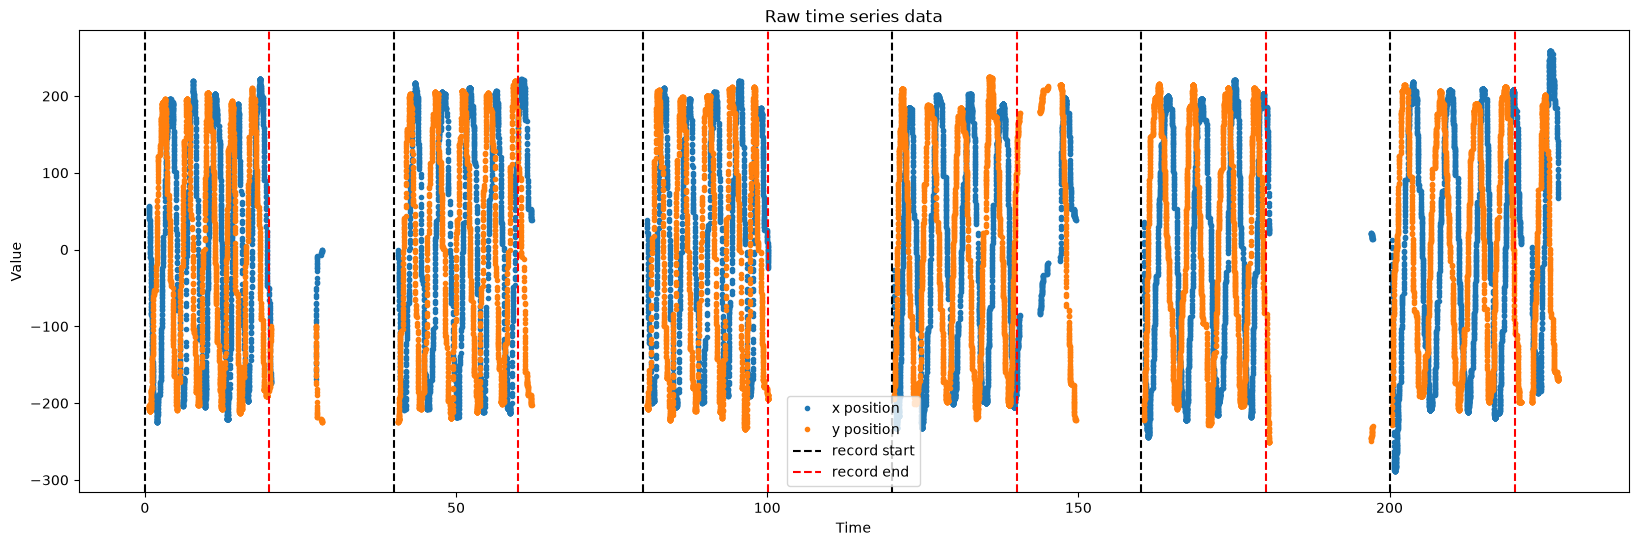

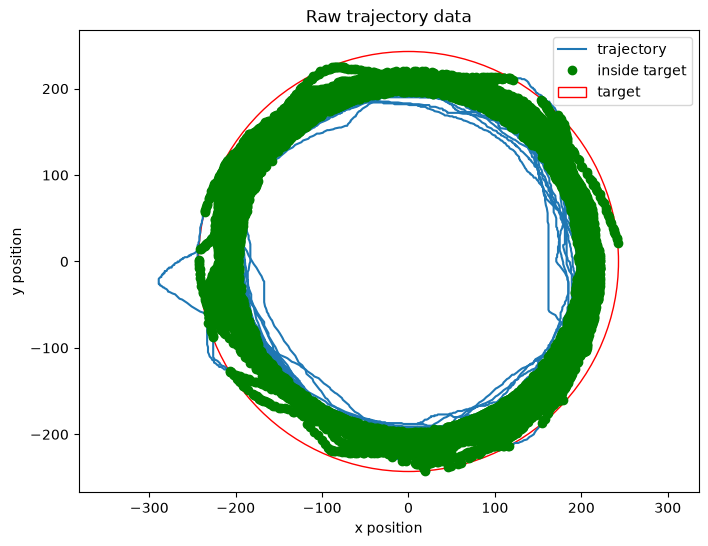

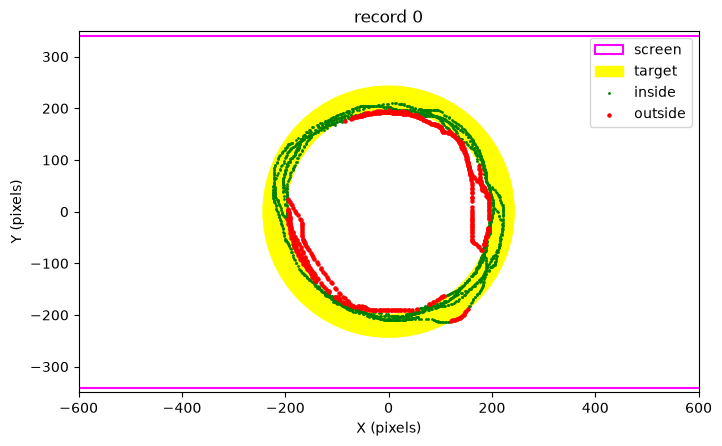

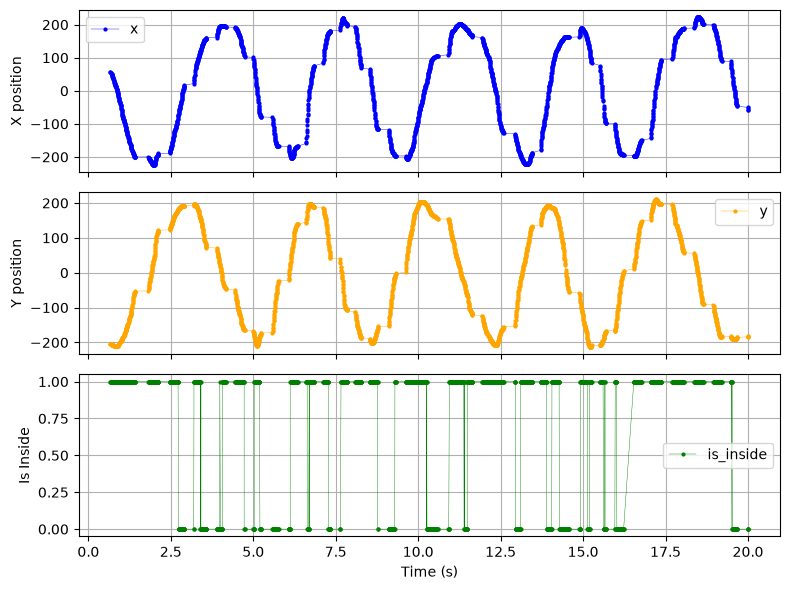

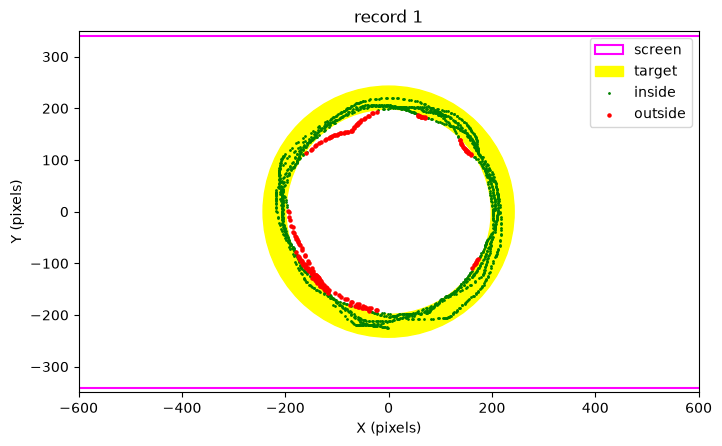

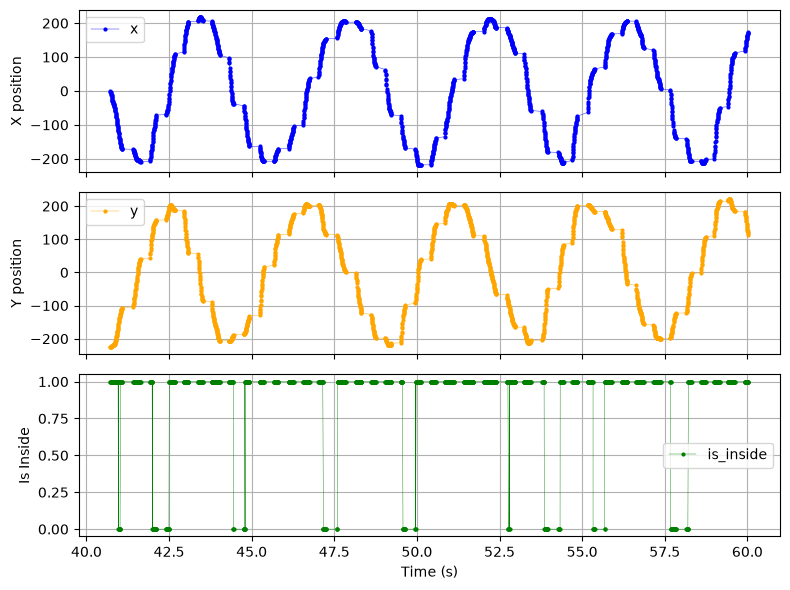

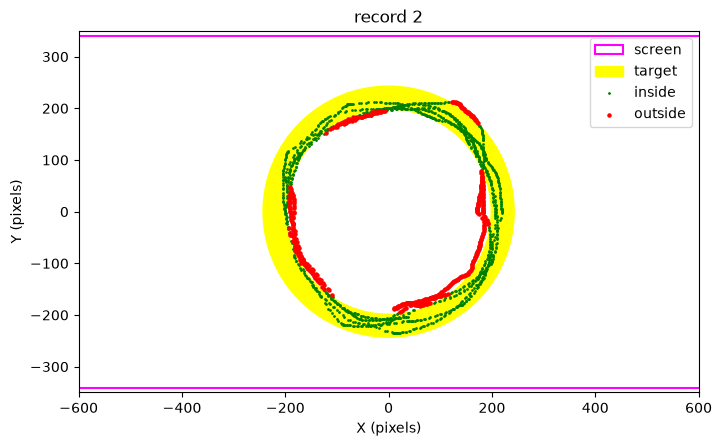

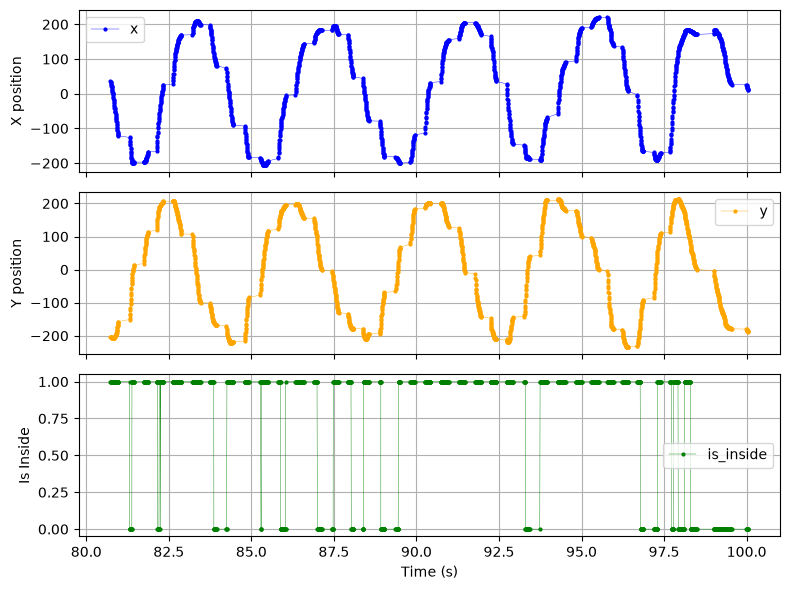

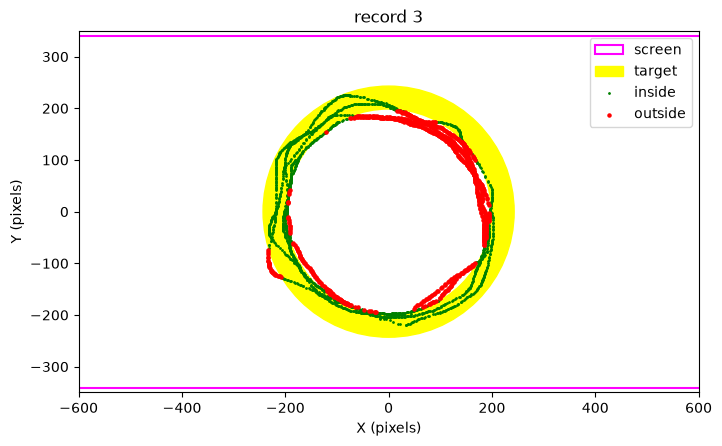

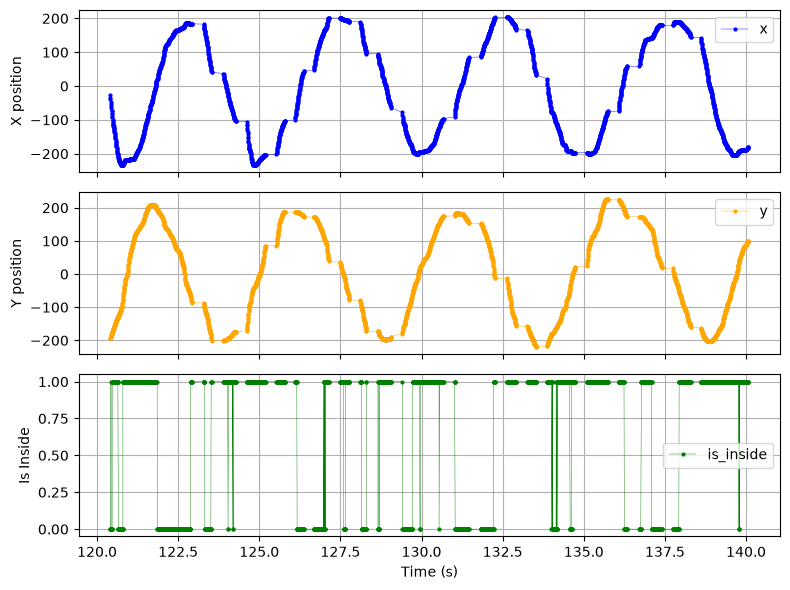

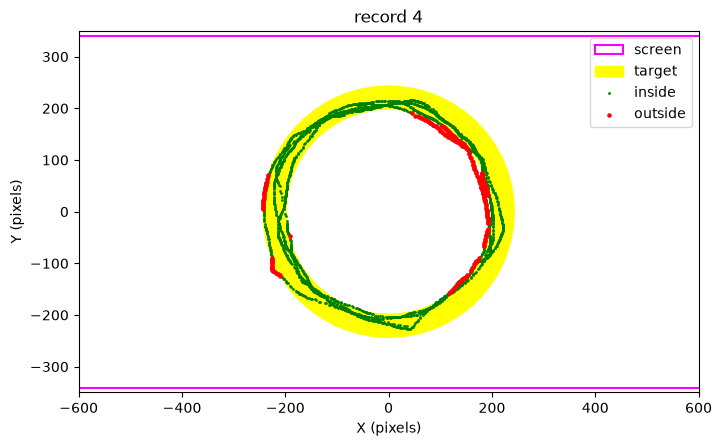

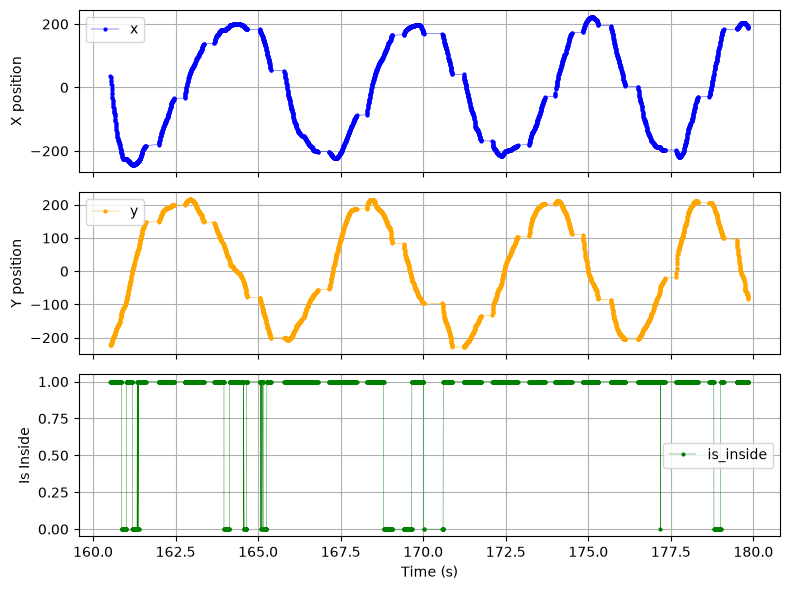

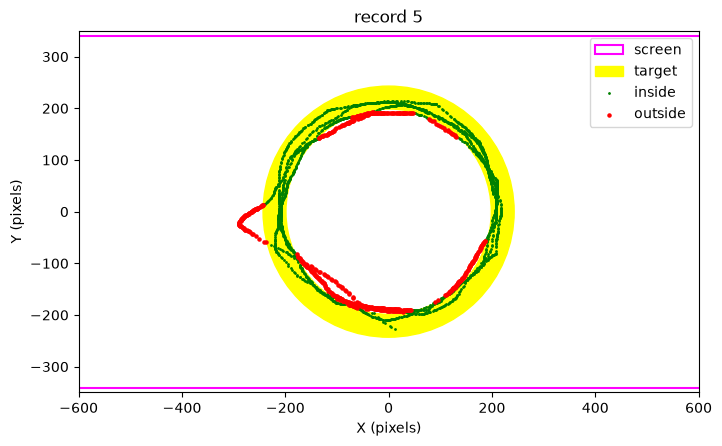

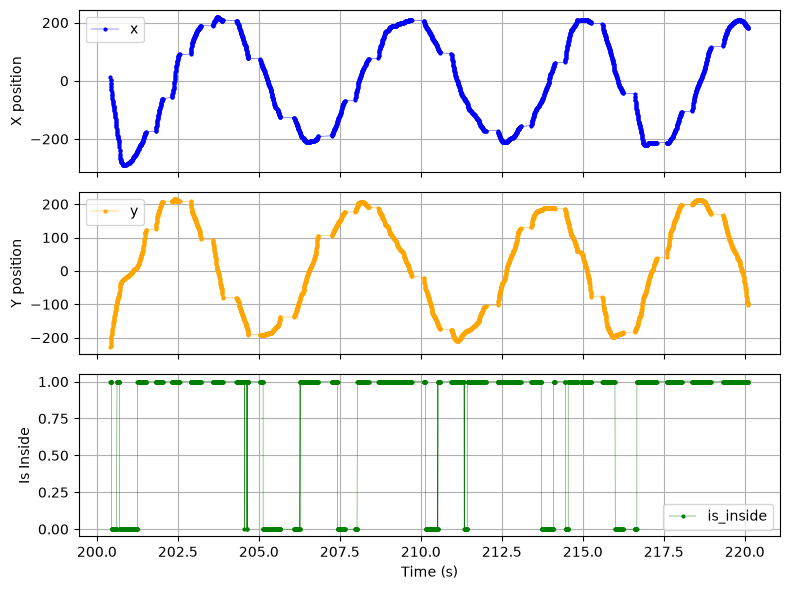

      Var |     nLaps |        Re |        Te |     error |    MT/lap |   IDe/lap |        Be |       IPe
---------------------------------------------------------------------------------------------------------
   Theory |      1.00 |    219.50 |     47.00 |      3.88 |           |           |      1.00 |          
   Rec001 |     -5.09 |    203.94 |     55.58 |     30.67 |      3.80 |     23.06 |      1.18 |      6.07
   Rec002 |     -4.66 |    207.35 |     44.22 |     14.04 |      4.14 |     29.46 |      0.94 |      7.11
   Rec003 |     -5.02 |    206.93 |     60.94 |     27.63 |      3.85 |     21.33 |      1.30 |      5.55
   Rec004 |     -4.29 |    202.63 |     66.02 |     35.99 |      4.58 |     19.28 |      1.40 |      4.21
   Rec005 |     -3.84 |    210.09 |     52.80 |     12.67 |      5.03 |     25.00 |      1.12 |      4.97
   Rec006 |     -3.84 |    208.32 |     66.95 |     23.44 |      5.13 |     19.55 |      1.42 |      3.81


In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # go up to the project root folder

%run notebooks/01b_my_data.ipynb
%run notebooks/02_recompute_statistics.ipynb

## 3. How this notebook works

To keep the Part 1 and Part 2 notebooks unchanged for the sample data, we do not edit them. Instead:

1. `01b_my_data.ipynb` is a copy of Part 1 in which only the file paths and the task constants point to our data.
2. This notebook runs `01b_my_data.ipynb` (loading the samples, parsing the markers, splitting the records), then runs `02_recompute_statistics.ipynb`. Part 2 detects that the data is already loaded and reuses it, so it computes the statistics on our recording.



## 4. Result: comparison with the table written by MouseReMoCo

The table printed above was recomputed by our code from `generated_data.csv`. We compared it with the summary table at the end of `generated_marker.csv`:

- All 6 records were found and analysed. Unlike in the sample file, `Rec006` is a completed record here, so no empty placeholder row is needed.
- 37 of the 48 values are identical. 10 more differ by only 0.01 or 0.02 (the size of the last displayed digit). One value differs more: the error of `Rec004` (35.99 recomputed vs 35.88 reported, a gap of 0.11 percentage points). We did not investigate this difference; a possible source is a small difference in which samples are included at the start or end of a record.
- `nLaps` is negative, as in the sample file, so both recordings have the same direction of rotation and the signs are directly comparable.
- The analysis code therefore also works on new data recorded on a different screen, once the task constants are updated.

Reminder of the columns: `nLaps` (laps, the sign gives the direction), `Re` (mean radius), `Te` (effective tolerance), `error` (percentage of the angle travelled outside the target), `MT/lap` (time per lap), `IDe/lap` (effective difficulty per lap), `Be` (`Te` divided by the task tolerance) and `IPe` (effective performance in bit/s).


## 5. What the numbers say about our performance

| Measure | Sample file (5 records) | Our recording (6 records) |
|---|---|---|
| Laps per 20 s (absolute) | 10.84 to 14.74 | 3.84 to 5.09 |
| `MT/lap` (s) | 1.30 to 1.84 | 3.80 to 5.13 |
| `error` (%) | 0.13 to 3.90 | 12.67 to 35.99 |
| `Be` | 0.73 to 1.95 | 0.94 to 1.42 |
| `IPe` (bit/s) | 7.94 to 24.04 | 3.81 to 7.11 |

- Our laps are slower (3.8 to 5.1 s per lap against 1.3 to 1.8 s) and we leave the target much more often (about 13 to 36 % of the angle travelled, against under 4 % in the sample).
- `Be` is above 1 in five of six records: the lane we effectively used was wider than the 47 px we were given. Only `Rec002` (0.94) is below 1.
- `Rec002` (right hand) is our best record (`IPe` = 7.11 bit/s) and `Rec006` (left hand) the weakest (`IPe` = 3.81 bit/s). Even our best record is below the weakest record of the sample (7.94 bit/s).

**Right hand vs left hand** (mean of the three records for each hand):

| Measure | Right hand (`Rec001` to `Rec003`) | Left hand (`Rec004` to `Rec006`) |
|---|---|---|
| `IPe` (bit/s) | 6.24 | 4.33 |
| `MT/lap` (s) | 3.93 | 4.91 |
| `Te` (px) | 53.58 | 61.92 |
| `error` (%) | 24.11 | 24.03 |

- With the left hand we were slower, used a wider effective lane and had a lower `IPe`. Every right-hand `IPe` (5.55 to 7.11) is higher than every left-hand `IPe` (3.81 to 4.97). This goes in the same direction as the poster of Fauviaux et al. (2021), which reports a lower `IPe` for the non-dominant hand. The error percentage, however, is almost the same for both hands.
- Caution: we always used the left hand last, so hand and order of the records are mixed up. Fatigue or practice could produce the same pattern, and with three records per hand and a single session we cannot separate them.
- We did not investigate why our performance differs from the sample recording. Possible factors, none of which we tested, are our limited familiarity with the task (this was our third trial), the input device (the laptop's built-in mouse) and the hand used.